# 📈 Python for Finance: Feature Engineering with Pandas & NumPy
### *A Hands-On Workshop — 90 Minutes*

---

**What we'll cover today:**

| # | Topic | Finance Concept |
|---|-------|-----------------|
| 1 | Load & Explore Data | OHLCV Stock Data |
| 2 | Clean & Fix Data Types | Date Components |
| 3 | Create New Columns | Daily Return, Price Range |
| 4 | Rolling Windows | Moving Averages |
| 5 | Cumulative Returns | Portfolio Growth |
| 6 | Volatility | Risk Measurement |
| 7 | GroupBy Analysis | Sector & Monthly Summaries |
| 8 | Summary & Challenges | Review |

> **Dataset:** 2 years of daily price data for 5 US stocks — AAPL, MSFT, JPM, AMZN, XOM  
> **Libraries:** `pandas`, `numpy`, `matplotlib`  
> **Level:** Beginner-Intermediate — you've seen pandas before, now let's use it on real financial data!


## 0. Setup — Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Make all plots a bit wider and add a subtle grid
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

print("All libraries loaded ✅")


All libraries loaded ✅


---
## 1. Load & Explore the Data

### 🔑 Finance Term: **OHLCV Data**

Every trading day, a stock generates 5 key numbers:

| Column | Stands For | Meaning |
|--------|-----------|---------|
| **Open** | Opening Price | Price when the market opens (9:30 AM in the US) |
| **High** | Daily High | Highest price reached that day |
| **Low** | Daily Low | Lowest price reached that day |
| **Close** | Closing Price | Final price when the market closes |
| **Volume** | Shares Traded | Number of shares that changed hands |

> This **OHLCV format** is the most common format for stock data worldwide — used in trading algorithms, quant finance, risk models, and ML.


In [ ]:
df = pd.read_csv('data_stock.csv', parse_dates=['Date'])
# df = pd.read_csv('https://raw.githubusercontent.com/ash322ash422/data/refs/heads/main/data_stock.csv', parse_dates=['Date'])
print(f"Shape: {df.shape}  →  {df.shape[0]} rows × {df.shape[1]} columns")
df.head(10)


Shape: (2600, 8)  →  2600 rows × 8 columns


,Date,Ticker,Sector,Open,High,Low,Close,Volume
0,2022-01-03,AAPL,Technology,185.08,183.89,182.73,183.68,431562677
1,2022-01-04,AAPL,Technology,182.53,185.27,181.84,182.96,636363196
2,2022-01-05,AAPL,Technology,179.76,182.17,181.14,181.49,204799310
3,2022-01-06,AAPL,Technology,178.89,181.17,179.26,179.71,239448315
4,2022-01-07,AAPL,Technology,183.19,184.84,184.40,184.50,369554445
5,2022-01-10,AAPL,Technology,184.37,186.63,184.37,184.93,419323444
6,2022-01-11,AAPL,Technology,182.01,185.69,182.96,182.98,731986373
7,2022-01-12,AAPL,Technology,177.83,179.31,176.21,179.01,535349636
8,2022-01-13,AAPL,Technology,181.17,181.70,181.28,181.45,231650193
9,2022-01-14,AAPL,Technology,179.46,179.81,177.64,179.15,200932567


In [4]:
# How many companies? How many days each?

print("Tickers:", df['Ticker'].unique())
print("Sectors:", df['Sector'].unique())
print("Date range:", df['Date'].min().date(), "→", df['Date'].max().date())
print()
print("Rows per ticker:")
print(df['Ticker'].value_counts())


Tickers: ['AAPL' 'MSFT' 'JPM' 'AMZN' 'XOM']
Sectors: ['Technology' 'Finance' 'Consumer' 'Energy']
Date range: 2022-01-03 → 2023-12-29

Rows per ticker:
Ticker
AAPL    520
MSFT    520
JPM     520
AMZN    520
XOM     520
Name: count, dtype: int64


In [5]:
# Quick statistical overview — always do this first!
df.describe()


,Date,Open,High,Low,Close,Volume
count,2600,2600.000000,2600.000000,2600.000000,2600.000000,2.600000e+03
mean,2022-12-31 12:00:00,177.909912,179.084662,176.787988,177.932912,5.534859e+08
min,2022-01-03 00:00:00,51.820000,52.180000,51.250000,51.800000,9.910080e+07
25%,2022-07-03 06:00:00,121.485000,122.167500,120.912500,121.322500,3.541286e+08
50%,2022-12-31 12:00:00,170.355000,171.380000,169.395000,170.385000,4.873842e+08
75%,2023-06-30 18:00:00,205.392500,206.905000,204.090000,205.307500,6.889137e+08
max,2023-12-29 00:00:00,378.150000,380.450000,374.470000,377.510000,3.330425e+09
std,NaN,83.802665,84.360902,83.237538,83.800305,2.882961e+08


---
## 2. Clean the Data & Fix Data Types

Real-world financial data is often messy. Before any analysis, we:
1. Check for **missing values**
2. Verify **data types** are correct
3. Extract **useful features from dates**


In [6]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Data types:")
print(df.dtypes)


Missing values per column:
Date      0
Ticker    0
Sector    0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Data types:
Date      datetime64[ns]
Ticker            object
Sector            object
Open             float64
High             float64
Low              float64
Close            float64
Volume             int64
dtype: object


In [7]:
# Extract useful time components from the Date column
# This is very common in finance for seasonal/trend analysis

df['Year']      = df['Date'].dt.year
df['Month']     = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.day_name()   # Monday, Tuesday, ...
df['Quarter']   = df['Date'].dt.quarter

df[['Date', 'Year', 'Month', 'DayOfWeek', 'Quarter']].head(6)


,Date,Year,Month,DayOfWeek,Quarter
0,2022-01-03,2022,1,Monday,1
1,2022-01-04,2022,1,Tuesday,1
2,2022-01-05,2022,1,Wednesday,1
3,2022-01-06,2022,1,Thursday,1
4,2022-01-07,2022,1,Friday,1
5,2022-01-10,2022,1,Monday,1


In [8]:
# Sanity check: High should ALWAYS be >= Low
# If not, we have bad data
bad_rows = df[df['High'] < df['Low']]
print(f"Rows where High < Low: {len(bad_rows)}")  # should be 0

# Also check: Close should be between Low and High
bad_close = df[(df['Close'] > df['High']) | (df['Close'] < df['Low'])]
print(f"Rows where Close is outside High-Low range: {len(bad_close)}")


Rows where High < Low: 0
Rows where Close is outside High-Low range: 0


---
## 3. Feature Engineering — Creating New Columns

**Feature engineering** = using existing columns to create new, more informative ones.

This is one of the most valuable skills in data science — and pandas + numpy make it fast.

---

### 3.1 Daily Return

> **🔑 Finance Term: Daily Return**  
> How much did the stock *gain or lose* today, expressed as a percentage.

$$\text{Daily Return}_t = \frac{\text{Close}_t - \text{Close}_{t-1}}{\text{Close}_{t-1}}$$

In plain English: *"If I bought at yesterday's close and sold at today's close, what % did I make?"*

- Positive return → stock went up that day 🟢  
- Negative return → stock went down that day 🔴  


In [9]:
# Sort data: dates must be in order within each ticker
df = df.sort_values(['Ticker', 'Date']).reset_index(drop=True)

# pct_change() computes (x - x_prev) / x_prev — exactly our formula
# groupby() ensures we don't bleed returns across different tickers
df['Daily_Return'] = df.groupby('Ticker')['Close'].pct_change()

df[['Date', 'Ticker', 'Close', 'Daily_Return']].dropna().head(8)


,Date,Ticker,Close,Daily_Return
1,2022-01-04,AAPL,182.96,-0.003920
2,2022-01-05,AAPL,181.49,-0.008035
3,2022-01-06,AAPL,179.71,-0.009808
4,2022-01-07,AAPL,184.50,0.026654
5,2022-01-10,AAPL,184.93,0.002331
6,2022-01-11,AAPL,182.98,-0.010545
7,2022-01-12,AAPL,179.01,-0.021696
8,2022-01-13,AAPL,181.45,0.013631


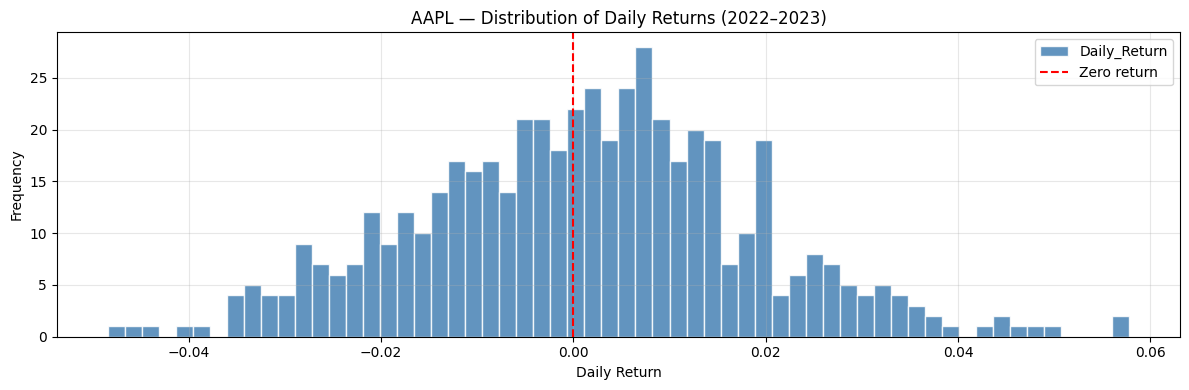

Average daily return : 0.0973%
Std deviation        : 1.7397%
Best day             : 5.78%
Worst day            : -4.84%


In [10]:
# Distribution of daily returns for AAPL
aapl = df[df['Ticker'] == 'AAPL'].copy()

ax = aapl['Daily_Return'].plot(
    kind='hist', bins=60, color='steelblue', edgecolor='white', alpha=0.85
)
ax.axvline(0, color='red', linewidth=1.5, linestyle='--', label='Zero return')
ax.set_xlabel('Daily Return')
ax.set_title('AAPL — Distribution of Daily Returns (2022–2023)')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Average daily return : {aapl['Daily_Return'].mean():.4%}")
print(f"Std deviation        : {aapl['Daily_Return'].std():.4%}")
print(f"Best day             : {aapl['Daily_Return'].max():.2%}")
print(f"Worst day            : {aapl['Daily_Return'].min():.2%}")


---
### 3.2 Daily Price Range

> **🔑 Finance Term: Intraday Range**  
> How much did the stock swing within a single trading day?

$$\text{Range} = \text{High} - \text{Low}$$

$$\text{Range\%} = \frac{\text{High} - \text{Low}}{\text{Close}} \times 100$$

A **large range** → volatile, uncertain day (earnings announcements, major news)  
A **small range** → calm, steady day


In [11]:
df['Range']     = df['High'] - df['Low']
df['Range_Pct'] = (df['Range'] / df['Close']) * 100

df[['Date', 'Ticker', 'High', 'Low', 'Close', 'Range', 'Range_Pct']].head(6)


,Date,Ticker,High,Low,Close,Range,Range_Pct
0,2022-01-03,AAPL,183.89,182.73,183.68,1.16,0.631533
1,2022-01-04,AAPL,185.27,181.84,182.96,3.43,1.874727
2,2022-01-05,AAPL,182.17,181.14,181.49,1.03,0.567524
3,2022-01-06,AAPL,181.17,179.26,179.71,1.91,1.062823
4,2022-01-07,AAPL,184.84,184.40,184.50,0.44,0.238482
5,2022-01-10,AAPL,186.63,184.37,184.93,2.26,1.222084


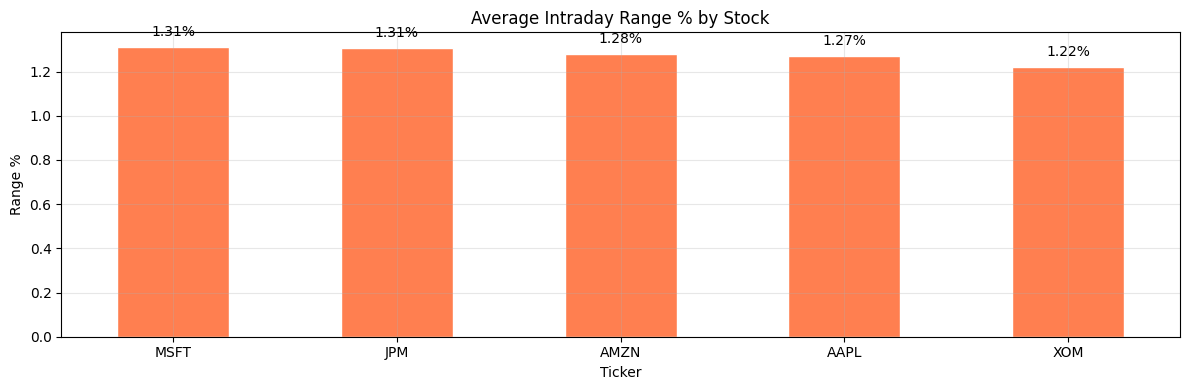

In [12]:
# Which ticker has the widest average daily range?
avg_range = df.groupby('Ticker')['Range_Pct'].mean().sort_values(ascending=False)

ax = avg_range.plot(kind='bar', color='coral', edgecolor='white', rot=0)
ax.set_title('Average Intraday Range % by Stock')
ax.set_ylabel('Range %')
for i, v in enumerate(avg_range):
    ax.text(i, v + 0.05, f'{v:.2f}%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()


---
### 3.3 Volume in Millions

Transforming units for readability — very common in financial reporting.


In [13]:
df['Volume_M'] = df['Volume'] / 1_000_000   # convert to millions

# Compare
print(f"Raw volume:         {df['Volume'].iloc[0]:,}")
print(f"Volume in millions: {df['Volume_M'].iloc[0]:.1f}M")


Raw volume:         431,562,677
Volume in millions: 431.6M


---
## 4. Rolling Windows — Moving Averages

> **🔑 Finance Term: Simple Moving Average (SMA)**  
> A rolling average of the closing price over the last **N** trading days.  
> Used to **smooth out day-to-day noise** and spot the underlying trend.

$$\text{SMA}_{N,\,t} = \frac{1}{N} \sum_{i=0}^{N-1} \text{Close}_{t-i}$$

| SMA | Window | Used for |
|-----|--------|----------|
| SMA-20 | ~1 month | Short-term trend |
| SMA-50 | ~2.5 months | Medium-term trend |
| SMA-200 | ~1 year | Long-term trend |

> 📌 **Golden Cross**: When the short-term SMA crosses *above* the long-term SMA → bullish signal 🟡  
> 📌 **Death Cross**: When the short-term SMA crosses *below* → bearish signal 💀


In [14]:
# .rolling(window).mean() — pandas makes this one line!
# transform() applies the function within each ticker group
df['SMA_20'] = df.groupby('Ticker')['Close'].transform(lambda x: x.rolling(20).mean())
df['SMA_50'] = df.groupby('Ticker')['Close'].transform(lambda x: x.rolling(50).mean())

# Note: first 19 rows won't have SMA_20 (not enough history yet)
df[df['Ticker'] == 'AAPL'][['Date', 'Close', 'SMA_20', 'SMA_50']].iloc[18:55]


,Date,Close,SMA_20,SMA_50
18,2022-01-27,188.42,NaN,NaN
19,2022-01-28,183.52,183.9575,NaN
20,2022-01-31,178.90,183.7185,NaN
21,2022-02-01,180.25,183.5830,NaN
22,2022-02-02,174.08,183.2125,NaN
23,2022-02-03,175.08,182.9810,NaN
24,2022-02-04,177.62,182.6370,NaN
25,2022-02-07,184.68,182.6245,NaN
26,2022-02-08,179.58,182.4545,NaN
27,2022-02-09,184.64,182.7360,NaN


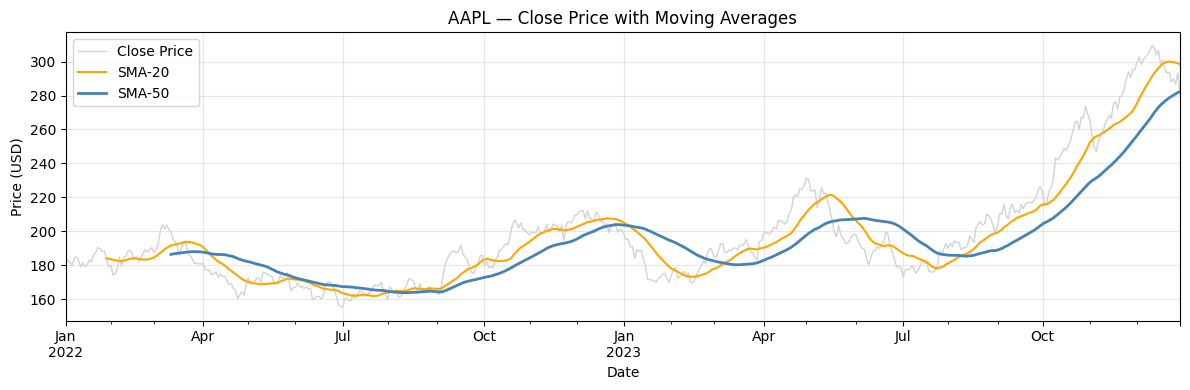

In [15]:
# Plot close price + both moving averages for AAPL
aapl = df[df['Ticker'] == 'AAPL'].set_index('Date')

ax = aapl['Close'].plot(label='Close Price', color='lightgray', linewidth=1)
aapl['SMA_20'].plot(ax=ax, label='SMA-20', color='orange', linewidth=1.5)
aapl['SMA_50'].plot(ax=ax, label='SMA-50', color='steelblue', linewidth=2)

ax.set_title('AAPL — Close Price with Moving Averages')
ax.set_ylabel('Price (USD)')
ax.legend()
plt.tight_layout()
plt.show()


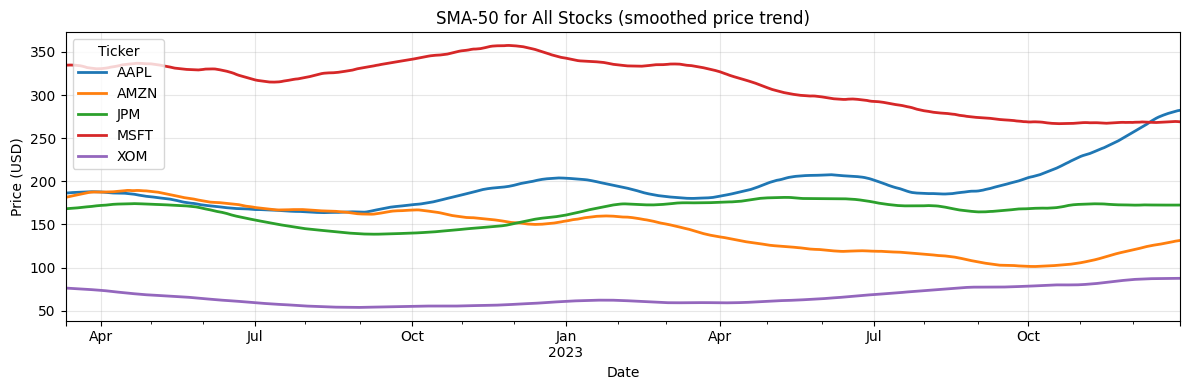

In [16]:
# Plot all 5 tickers — their SMA-50 to compare trends
sma50_pivot = df.pivot_table(index='Date', columns='Ticker', values='SMA_50')

ax = sma50_pivot.plot(linewidth=2)
ax.set_title('SMA-50 for All Stocks (smoothed price trend)')
ax.set_ylabel('Price (USD)')
ax.legend(title='Ticker')
plt.tight_layout()
plt.show()


---
## 5. Cumulative Returns — "How Much Would I Have Made?"

> **🔑 Finance Term: Cumulative Return**  
> Total percentage gain from the *start* of the period to today.  
> Answers: *"If I invested $1 on day 1, what is it worth now?"*

$$\text{Cumulative Return}_t = \left( \prod_{i=1}^{t} (1 + r_i) \right) - 1$$

In code: `(1 + daily_return).cumprod() - 1`

This **normalises** all stocks to the same starting point, so we can compare fairly — a $150 stock vs a $500 stock on equal footing.


In [17]:
df['Cum_Return'] = df.groupby('Ticker')['Daily_Return'].transform(
    lambda x: (1 + x).cumprod() - 1
)

df[['Date', 'Ticker', 'Close', 'Daily_Return', 'Cum_Return']].dropna().head(8)


,Date,Ticker,Close,Daily_Return,Cum_Return
1,2022-01-04,AAPL,182.96,-0.003920,-0.003920
2,2022-01-05,AAPL,181.49,-0.008035,-0.011923
3,2022-01-06,AAPL,179.71,-0.009808,-0.021614
4,2022-01-07,AAPL,184.50,0.026654,0.004464
5,2022-01-10,AAPL,184.93,0.002331,0.006805
6,2022-01-11,AAPL,182.98,-0.010545,-0.003811
7,2022-01-12,AAPL,179.01,-0.021696,-0.025425
8,2022-01-13,AAPL,181.45,0.013631,-0.012141


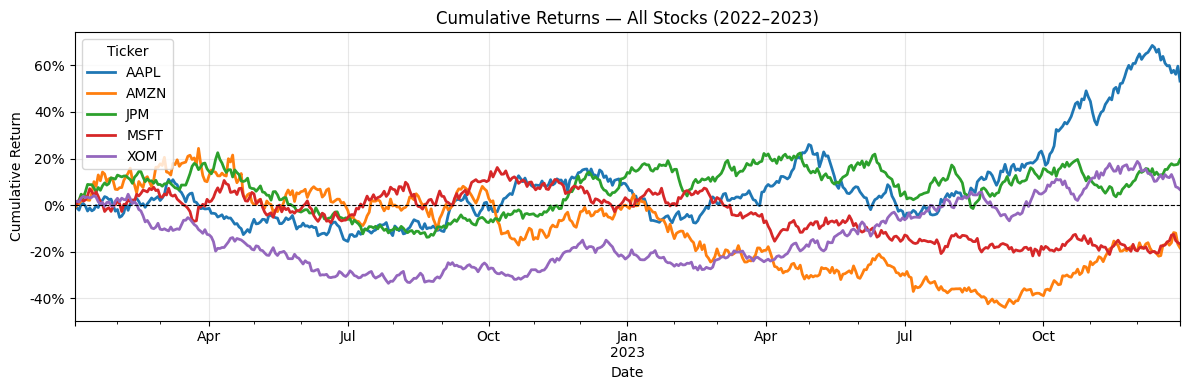

In [18]:
# Pivot so each ticker is a column, then plot
cum_pivot = df.pivot_table(index='Date', columns='Ticker', values='Cum_Return')

ax = cum_pivot.plot(linewidth=2)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('Cumulative Returns — All Stocks (2022–2023)')
ax.set_ylabel('Cumulative Return')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.legend(title='Ticker')
plt.tight_layout()
plt.show()


In [19]:
# Total return by the end of the period
final_returns = cum_pivot.iloc[-1].sort_values(ascending=False)
print("Total return over the 2-year period:")
for ticker, ret in final_returns.items():
    bar = '█' * int(abs(ret * 20))
    sign = '+' if ret > 0 else ''
    print(f"  {ticker}: {sign}{ret:.1%}  {bar}")


Total return over the 2-year period:
  AAPL: +53.2%  ██████████
  JPM: +19.5%  ███
  XOM: +6.7%  █
  MSFT: -16.6%  ███
  AMZN: -18.3%  ███


---
## 6. Volatility — Measuring Risk

> **🔑 Finance Term: Volatility**  
> The **standard deviation** of daily returns over a rolling window.  
> It measures how much prices fluctuate — a core measure of **risk**.

$$\sigma_{20,\,t} = \text{std}(r_{t-19},\, r_{t-18},\, \ldots,\, r_t)$$

| Volatility | What it means |
|-----------|--------------|
| Low (< 15%) | Stable, predictable (utility stocks, bonds) |
| Medium (15–30%) | Normal for large-cap stocks |
| High (> 30%) | Risky (small-caps, crypto, distressed companies) |

> 📌 **Annualised Volatility** = Rolling Volatility × √252  
> (252 = approximate number of trading days in a year)


In [20]:
# Rolling 20-day volatility
df['Volatility_20'] = df.groupby('Ticker')['Daily_Return'].transform(
    lambda x: x.rolling(20).std()
)

# Annualise: multiply by sqrt of trading days in a year
df['Ann_Volatility'] = df['Volatility_20'] * np.sqrt(252)

df[['Date', 'Ticker', 'Daily_Return', 'Volatility_20', 'Ann_Volatility']].dropna().head(6)


,Date,Ticker,Daily_Return,Volatility_20,Ann_Volatility
20,2022-01-31,AAPL,-0.025174,0.015352,0.243707
21,2022-02-01,AAPL,0.007546,0.015459,0.245406
22,2022-02-02,AAPL,-0.034230,0.017138,0.272055
23,2022-02-03,AAPL,0.005744,0.017115,0.271692
24,2022-02-04,AAPL,0.014508,0.016271,0.258287
25,2022-02-07,AAPL,0.039748,0.018732,0.297363


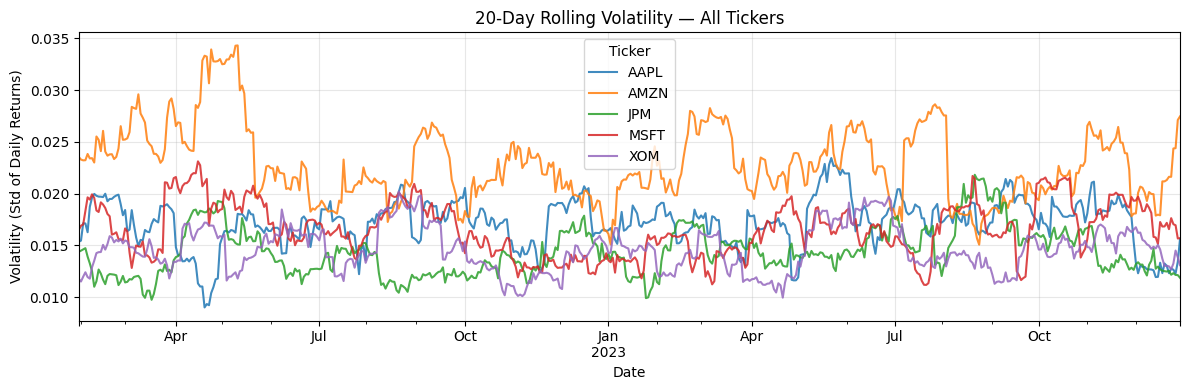

In [21]:
# Plot rolling volatility for all tickers
vol_pivot = df.pivot_table(index='Date', columns='Ticker', values='Volatility_20')

ax = vol_pivot.plot(linewidth=1.5, alpha=0.85)
ax.set_title('20-Day Rolling Volatility — All Tickers')
ax.set_ylabel('Volatility (Std of Daily Returns)')
ax.legend(title='Ticker')
plt.tight_layout()
plt.show()


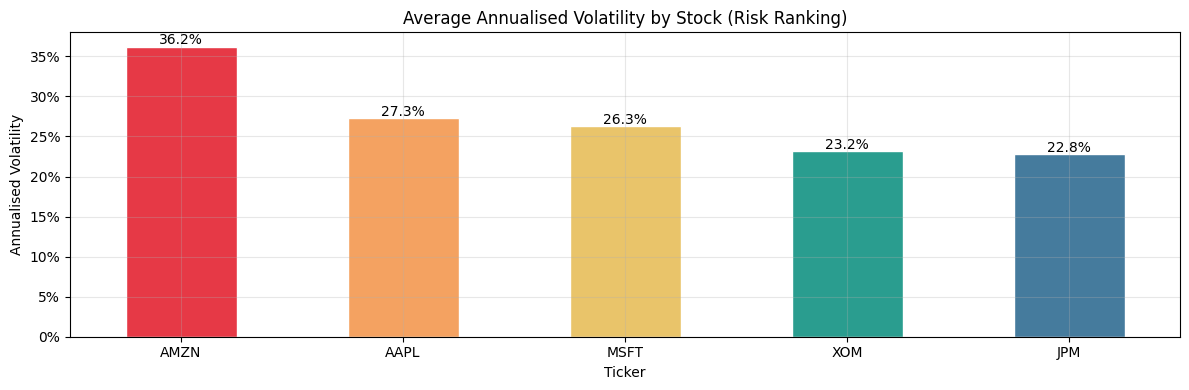

Reminder: Higher volatility = higher risk (and potentially higher reward)


In [23]:
# Average annualised volatility — who's riskiest?
avg_vol = df.groupby('Ticker')['Ann_Volatility'].mean().sort_values(ascending=False)

colors = ['#e63946', '#f4a261', '#e9c46a', '#2a9d8f', '#457b9d']
ax = avg_vol.plot(kind='bar', color=colors, edgecolor='white', rot=0)
ax.set_title('Average Annualised Volatility by Stock (Risk Ranking)')
ax.set_ylabel('Annualised Volatility')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
for i, v in enumerate(avg_vol):
    ax.text(i, v + 0.003, f'{v:.1%}', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

print("Reminder: Higher volatility = higher risk (and potentially higher reward)")


---
## 7. GroupBy Analysis — Aggregating Insights

`groupby()` is pandas' superpower. In finance, we constantly need summaries:
- Returns by **sector**
- Volume by **month**
- Risk by **ticker**

Let's put it all together.


In [24]:
# Summary by sector
sector_summary = df.groupby('Sector').agg(
    Avg_Daily_Return =('Daily_Return', 'mean'),
    Avg_Volatility   =('Volatility_20', 'mean'),
    Total_Volume_B   =('Volume', 'sum'),
    Num_Stocks       =('Ticker', 'nunique')
).round(4)

sector_summary['Total_Volume_B'] = (sector_summary['Total_Volume_B'] / 1e9).round(1)
sector_summary.columns = ['Avg Daily Return', 'Avg 20d Volatility', 'Total Volume (B shares)', 'Num Stocks']
sector_summary


,Avg Daily Return,Avg 20d Volatility,Total Volume (B shares),Num Stocks
Sector,,,,
Consumer,-0.0001,0.0228,287.1,1
Energy,0.0002,0.0146,286.9,1
Finance,0.0004,0.0144,284.1,1
Technology,0.0004,0.0169,580.9,2


In [25]:
# Monthly average returns — useful for seasonality analysis
monthly = df.groupby(['Ticker', 'Month'])['Daily_Return'].mean().reset_index()

# Pivot so each ticker is a column, months are rows
monthly_pivot = monthly.pivot(index='Month', columns='Ticker', values='Daily_Return')
monthly_pivot.index = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

monthly_pivot


Ticker,AAPL,AMZN,JPM,MSFT,XOM
Jan,-0.004468,-0.001096,0.003067,-0.000432,-0.000190
Feb,0.004363,-0.000728,-0.001310,0.001826,-0.001811
Mar,-0.000343,-0.000166,0.003631,-0.002687,-0.001231
Apr,0.002142,-0.005078,-0.002736,0.000155,0.000495
May,-0.003024,0.001584,-0.002064,-0.001002,0.000595
Jun,-0.003744,-0.001351,-0.003071,-0.002597,-0.000906
Jul,0.002905,-0.001920,0.000122,0.002572,0.001267
Aug,0.001158,-0.002855,-0.000708,-0.000171,-0.000287
Sep,0.005981,0.003954,0.002300,0.001096,0.003392
Oct,0.005804,-0.000315,0.000788,0.000397,0.000417


In [ ]:
# Plot monthly average return for each ticker as a line
ax = monthly_pivot.plot(marker='o', linewidth=2)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('Average Daily Return by Month (Seasonality)')
ax.set_ylabel('Avg Daily Return')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.2%}'))
ax.legend(title='Ticker')
plt.tight_layout()
plt.show()


In [26]:
# Correlation between stocks — do they move together?
# Pivot Close prices, compute % changes, then correlate
close_pivot = df.pivot_table(index='Date', columns='Ticker', values='Close')
return_corr = close_pivot.pct_change().corr()

print("Return Correlation Matrix:")
print(return_corr.round(3))


Return Correlation Matrix:
Ticker   AAPL   AMZN    JPM   MSFT    XOM
Ticker                                   
AAPL    1.000 -0.035  0.019 -0.027  0.007
AMZN   -0.035  1.000 -0.022  0.066 -0.004
JPM     0.019 -0.022  1.000  0.004 -0.053
MSFT   -0.027  0.066  0.004  1.000 -0.100
XOM     0.007 -0.004 -0.053 -0.100  1.000


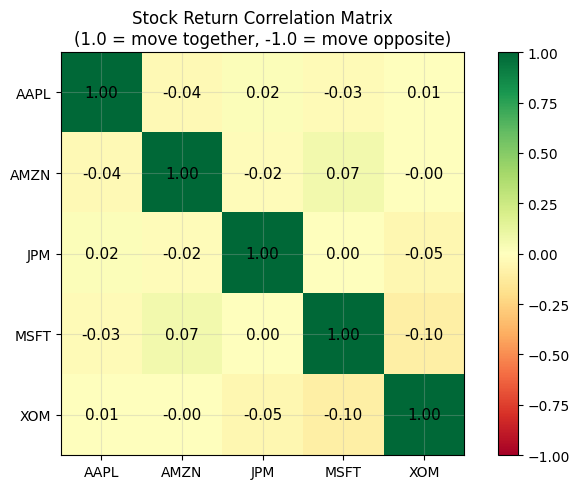

Highly correlated stocks move together — less diversification benefit!


In [27]:
# Visualise the correlation matrix as a colour-coded table
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(return_corr, cmap='RdYlGn', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax)

tickers = return_corr.columns.tolist()
ax.set_xticks(range(len(tickers)))
ax.set_yticks(range(len(tickers)))
ax.set_xticklabels(tickers)
ax.set_yticklabels(tickers)

# Add value labels inside each cell
for i in range(len(tickers)):
    for j in range(len(tickers)):
        ax.text(j, i, f"{return_corr.iloc[i,j]:.2f}", ha='center', va='center', fontsize=11)

ax.set_title('Stock Return Correlation Matrix\n(1.0 = move together, -1.0 = move opposite)')
plt.tight_layout()
plt.show()

print("Highly correlated stocks move together — less diversification benefit!")


---
## 8. Summary — What We Built Today

Let's see all the new columns we engineered:


In [28]:
original_cols = ['Date', 'Ticker', 'Sector', 'Open', 'High', 'Low', 'Close', 'Volume']
new_cols = [c for c in df.columns if c not in original_cols]

print(f"Started with {len(original_cols)} columns: {original_cols}")
print(f"\nEngineered {len(new_cols)} new columns:")
for c in new_cols:
    print(f"  • {c}")


Started with 8 columns: ['Date', 'Ticker', 'Sector', 'Open', 'High', 'Low', 'Close', 'Volume']

Engineered 13 new columns:
  • Year
  • Month
  • DayOfWeek
  • Quarter
  • Daily_Return
  • Range
  • Range_Pct
  • Volume_M
  • SMA_20
  • SMA_50
  • Cum_Return
  • Volatility_20
  • Ann_Volatility


In [29]:
# Final enriched dataset
df[['Date', 'Ticker', 'Close', 'Daily_Return', 'SMA_20', 'SMA_50',
    'Cum_Return', 'Volatility_20', 'Ann_Volatility']].dropna().tail(8)


,Date,Ticker,Close,Daily_Return,SMA_20,SMA_50,Cum_Return,Volatility_20,Ann_Volatility
2592,2023-12-20,XOM,88.15,0.016607,89.1540,87.4024,0.130853,0.013004,0.206439
2593,2023-12-21,XOM,87.35,-0.009075,88.9635,87.4196,0.120590,0.013030,0.206849
2594,2023-12-22,XOM,87.13,-0.002519,88.7470,87.4672,0.117768,0.012969,0.205884
2595,2023-12-25,XOM,88.19,0.012166,88.6725,87.5102,0.131366,0.012698,0.201567
2596,2023-12-26,XOM,86.53,-0.018823,88.4935,87.5648,0.110071,0.013240,0.210183
2597,2023-12-27,XOM,84.08,-0.028314,88.2055,87.5746,0.078640,0.014497,0.230134
2598,2023-12-28,XOM,83.80,-0.003330,87.8360,87.6170,0.075048,0.013849,0.219838
2599,2023-12-29,XOM,83.14,-0.007876,87.3640,87.6462,0.066581,0.013091,0.207812


---
## 🎯 Key Pandas & NumPy Skills In this Session

| Tool | What it Does | Where We Used It |
|------|-------------|-----------------|
| `parse_dates` | Auto-convert strings to datetime | Loading data |
| `dt.year`, `dt.month` | Extract date parts | Date features |
| `pct_change()` | % change between rows | Daily Return |
| `groupby().transform()` | Apply function within groups | Returns, Rolling |
| `rolling(N).mean()` | Rolling average | SMA-20, SMA-50 |
| `rolling(N).std()` | Rolling std deviation | Volatility |
| `cumprod()` | Cumulative product | Cumulative Return |
| `np.sqrt(252)` | Annualisation factor | Ann. Volatility |
| `pivot_table()` | Reshape data | Comparison charts |
| `groupby().agg()` | Multi-column aggregation | Sector summaries |
| `.corr()` | Correlation matrix | Portfolio analysis |

---

## 📚 Finance Terms We Covered

| Term | Definition |
|------|-----------|
| **OHLCV** | Open, High, Low, Close, Volume — the standard daily stock data format |
| **Daily Return** | Percentage change in price from one day to the next |
| **Intraday Range** | High − Low on a given day; measures daily price swing |
| **SMA (Moving Average)** | Rolling average of closing prices; reveals the trend |
| **Golden Cross** | SMA-short crossing above SMA-long; a bullish signal |
| **Cumulative Return** | Total % gain from the start date; normalises across stocks |
| **Volatility** | Std deviation of returns; the classic measure of risk |
| **Annualised Volatility** | Volatility scaled to a yearly figure using × √252 |
| **Correlation** | How similarly two stocks move; key for diversification |



---

## Take-Home Challenges

**Challenge 1 — Bollinger Bands** *(Medium)*  
Add two new columns:
```python
df['BB_Upper'] = df['SMA_20'] + 2 * df['Volatility_20']
df['BB_Lower'] = df['SMA_20'] - 2 * df['Volatility_20']
```
Plot them along with SMA_20 for MSFT. What do you notice when the price touches the bands?

**Challenge 2 — Best Day of the Week** *(Easy)*  
Which weekday (Mon–Fri) has the highest average return for AAPL?  
*Hint:* `df[df['Ticker']=='AAPL'].groupby('DayOfWeek')['Daily_Return'].mean()`

**Challenge 3 — Max Drawdown** *(Hard)*  
A **drawdown** measures how far a stock has fallen from its peak.  
$$\text{Drawdown}_t = \frac{\text{Price}_t - \text{Peak Price up to } t}{\text{Peak Price up to } t}$$  
*Hint:* `rolling_max = df.groupby('Ticker')['Close'].transform(lambda x: x.cummax())`  
Then compute `(Close - rolling_max) / rolling_max`. What was XOM's worst drawdown?

**Challenge 4 — Sharp Ratio** *(Medium)*  
$$\text{Sharpe Ratio} = \frac{\text{Mean Daily Return}}{\text{Std of Daily Returns}} \times \sqrt{252}$$  
Compute it for each ticker. Which stock gave the best return *per unit of risk*?

---
*Good luck!* 🏦
